In [1]:
import os
import operator
from dotenv import load_dotenv

from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from typing import Annotated, TypedDict
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

d:\Data Science and Machine Learning\Data Science and Gen AI Data - 2026\Agentic AI\Codes\newenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

# Call Model
llm = ChatGroq(model="openai/gpt-oss-120b")

In [3]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [4]:
def chat_node(state: ChatState):
    # Take user query from state
    messages = state['messages']

    # Send to LLM
    response = llm.invoke(messages)

    # Store response from LLM to state
    return {'messages': [response]}

In [5]:
graph = StateGraph(ChatState)
checkpointer = MemorySaver()

# Add nodes
graph.add_node("chat_node", chat_node)

# Add edges
graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

chatbot = graph.compile(checkpointer=checkpointer)

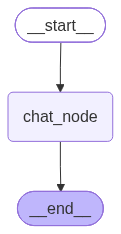

In [6]:
chatbot

In [9]:
# initial_state = {
#     'messages': [HumanMessage(content="What is the capital of India?")]
# }

# result = chatbot.invoke(initial_state)['messages'][-1].content
# print('AI:', result)

## Without Stream

In [ ]:
thread_id = '1'


while True:
    user_message = input("Type your question: ")
    print('User:', user_message)
    if user_message.strip().lower() in ['bye', 'stop', 'exit']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    result = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)['messages'][-1].content
    print('AI:', result)

## With Stream

In [19]:
thread_id = '1'
config = {'configurable': {'thread_id': thread_id}}

while True:
    user_message = input("Type your question: ")
    print('User:', user_message)

    if user_message.strip().lower() in ['bye', 'stop', 'exit']:
        break

    print('AI:')

    for message_chunk, metadata in chatbot.stream(
        {'messages': [HumanMessage(content=user_message)]},
        config=config,
        stream_mode="messages"
    ):
        # Print only text chunks coming from the chat node
        if message_chunk.content and metadata.get('langgraph_node') == 'chat_node':
            print(message_chunk.content, end='', flush=True)

    print()

User: Hello
AI:
I’m doing great, thanks for asking! How can I help you today?
User: What is meant by an Agentic AI?
AI:
### “Agentic AI” – What the Term Means and Why It Matters  

| Aspect | What it refers to | Typical examples | Key take‑aways |
|--------|------------------|------------------|----------------|
| **Agency** | The capacity to *act* on the world in pursuit of a goal, rather than merely *respond* to a prompt. | A virtual personal assistant that can schedule meetings, order groceries, and follow‑up on tasks without a new user command each time. | The AI is treated as an *actor* with its own (programmed) intentions. |
| **Autonomy** | The ability to make decisions *independently* of direct human instruction, within the bounds of its design and constraints. | A reinforcement‑learning robot that learns to navigate a warehouse and optimizes its own route planning. | Autonomy is a spectrum—from tightly constrained scripts to open‑ended self‑directed planning. |
| **Goal‑direct

In [17]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='af874766-d47f-4723-b88a-f71db35fac7e'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We should respond politely. No special instructions. Use friendly greeting.'}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 72, 'total_tokens': 110, 'completion_time': 0.08278463, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.014217024, 'prompt_tokens_details': None, 'queue_time': 0.349757513, 'total_time': 0.097001654}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_f640395b96', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a17b88-b062-75f2-9032-fb34d92c4c7a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 38, 'total_tokens': 110, 'output_to